# Dokumentacja Wstępna
- Jakub Kwaśniak
- Michał Mizia

## Problem Biznesowy

### Opis

- Czasami oferenci zawyżają ceny, aby nikt w danym okresie nie rezerwował u nich noclegów – jakoś musimy to wykrywać, żeby dało się odpowiednio reagować.

### Cel Biznesowy

- ...

### Biznesowe kryterium sukcesu

- ...

## Zadanie modelowania

### Sposób rozwiązania zadania modelowania

Przygotowanie i porównanie dwóch modeli rozwiązujących przedstawiony problem klasyfikacji binarnej:
- modelu bazowego: ...
- modelu  

### Analityczne kryterium sukcesu

- ...

## Analiza Danych

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pprint import pprint

In [40]:
users_df = pd.read_csv("../data/users.csv", skip_blank_lines=False)
users_df.head()

,id,name,surname,city,street,street_number,postal_code
0,45098287,Fryderyk,Raczyński,Nowa Sól,Kisielewskiego Stefana,1072,74-140
1,508887029,Ewa,Szklarska,Cybinka,Ławica,232,61-698
2,367991462,Kostek,Dębicki,Radzyń Chełmiński,Rollego Karola,437,48-273
3,443643923,Hanna,Lutostańska,Bystrzyca Kłodzka,Karwowskiego Stanisława,1187,11-432
4,235036339,Ryszard,Kot,Karpacz,Nowickiego Maksymiliana,1251,51-128


- początkowo, przeanalizowaliśmy z jakich miejscowości pochodzi najwięcej klientów portalu 'Nocarz'

Łącznie miast: 915
Najmniej klientów - Nowy Staw osob - pochodzi z 30,      a najwięcej klientów - Leżajsk osob - pochodzi z 98


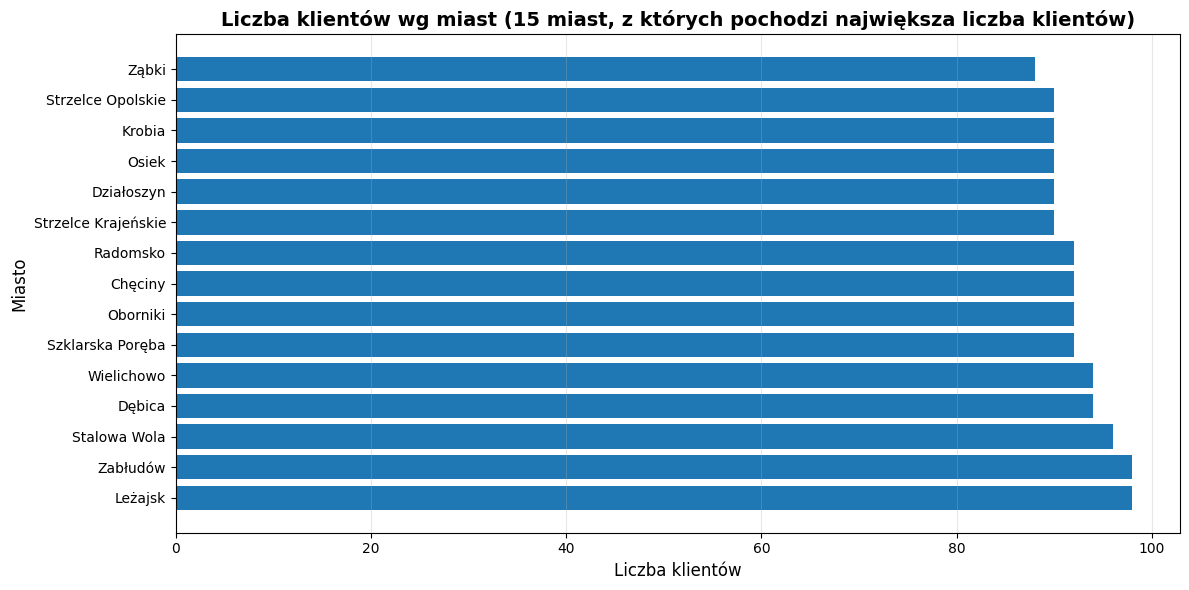

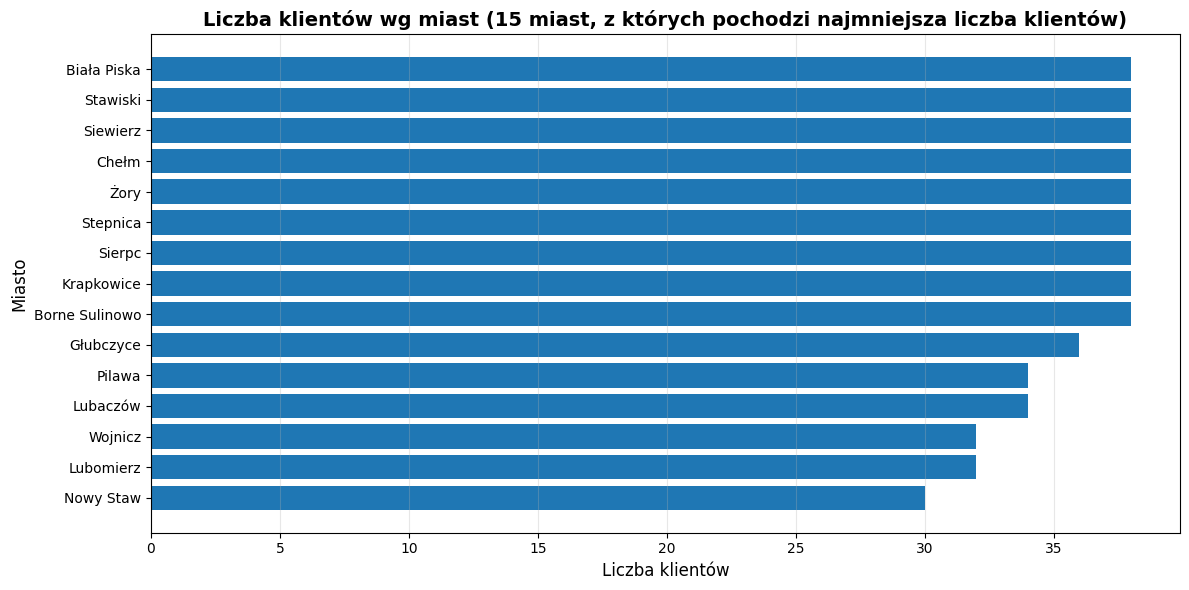

In [113]:

clients_by_city = users_df["city"].value_counts()
print(f"Łącznie miast: {len(clients_by_city)}")

clients_by_city_desc = clients_by_city.sort_values(ascending=False)
clients_by_city_asc = clients_by_city.sort_values(ascending=True)
clients_by_city_asc.values
print(f"Najmniej klientów - {clients_by_city_asc.index[0]} osob - pochodzi z {clients_by_city_asc.values[0]},\
      a najwięcej klientów - {clients_by_city_desc.index[0]} osob - pochodzi z {clients_by_city_desc.values[0]}")


clients_by_city_desc = clients_by_city_desc.head(15)
plt.figure(figsize=(12, 6))
plt.barh(range(len(clients_by_city_desc)), clients_by_city_desc.values)
plt.yticks(range(len(clients_by_city_desc)), clients_by_city_desc.index)
plt.xlabel('Liczba klientów', fontsize=12)
plt.ylabel('Miasto', fontsize=12)
plt.title('Liczba klientów wg miast (15 miast, z których pochodzi największa liczba klientów)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

clients_by_city_asc = clients_by_city_asc.head(15)
plt.figure(figsize=(12, 6))
plt.barh(range(len(clients_by_city_asc)), clients_by_city_asc.values)
plt.yticks(range(len(clients_by_city_asc)), clients_by_city_asc.index)
plt.xlabel('Liczba klientów', fontsize=12)
plt.ylabel('Miasto', fontsize=12)
plt.title('Liczba klientów wg miast (15 miast, z których pochodzi najmniejsza liczba klientów)', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


- ponizej przygotowane zostały dane z sesji ('sessions') i opinie ('reviews') uytkowników, potrzebne do dalszych analiz  

In [53]:
sessions_df = pd.read_csv("../data/sessions.csv", skip_blank_lines=False)
sessions_df.head(n=10)

,action,user_id,timestamp,listing_id,booking_date,booking_duration,booking_id
0,browse_listings,692150,2011-11-07T08:50:32.303992,NaN,NaN,NaN,NaN
1,view_listing,692150,2011-11-07T08:51:14.303992,48673134.0,NaN,NaN,NaN
2,view_listing,692150,2011-11-07T09:31:40.303992,42488063.0,NaN,NaN,NaN
3,view_listing,692150,2011-11-07T10:31:23.303992,20408758.0,NaN,NaN,NaN
4,view_listing,692150,2011-11-07T10:31:23.303992,477515.0,NaN,NaN,NaN
5,book_listing,692150,2011-11-07T10:31:23.303992,477515.0,2011-12-13,6.0,e537b4cf-b5f3-4f62-b207-c6352c1c43fc
6,browse_listings,3077455,2011-09-16T04:26:04.675611,NaN,NaN,NaN,NaN
7,view_listing,3077455,2011-09-16T04:50:28.675611,496570.0,NaN,NaN,NaN
8,view_listing,3077455,2011-09-16T05:04:04.675611,35584798.0,NaN,NaN,NaN
9,view_listing,3077455,2011-09-16T05:04:18.675611,51851190.0,NaN,NaN,NaN


In [54]:
reviews_df = pd.read_csv("../data/reviews.csv", skip_blank_lines=False)
reviews_df.head()

,listing_id,id,date,reviewer_id,comments,numerical_review
0,477515,1875754,2012-08-03,692150,"Terrific place, terrific location. Highly reco...",5
1,477515,1928602,2012-08-08,3077455,This apartment is fantastic! We were 4 people...,5
2,477515,2092188,2012-08-25,3052845,"The apartment was perfect!\r<br/>Well located,...",4
3,477515,2294712,2012-09-14,1299244,"Thanks Torsten and Amber for the great stay, t...",5
4,477515,2344903,2012-09-19,395390,I cannot recommend this apartment enough for t...,5


- w następnych analizach wykorzystane zostaną rózniez dane 'kalendarza dostępności i rezerwacji' (calendar) oraz spisu ofert (listings) noclegów w portalu nocarz, posłuzą one do przewidywań występowania / wykrycia anomalii w cenach noclegów 

In [55]:
listings_df = pd.read_csv("../data/listings.csv", skip_blank_lines=False)   # can add index_col="id"
listings_df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,28806732,https://www.nocarz.pl/rooms/28806732,20241221052002,2024-12-21,previous scrape,Neukölln Home,"Loft bed, fold out couch, kitchen and balcony ...",Plenty of neighbourhood bars and cafes to keep...,https://a0.muscache.com/pictures/60151487-cc67...,217262525,...,5.00,4.60,4.40,NaN,f,1,1,0,0,0.07
1,1177924,https://www.nocarz.pl/rooms/1177924,20241221052002,2024-12-21,city scrape,Bella Souterrain im Bergmannkiez,The apartment is centrally located in Berlin i...,One of the best locations in Berlin: The holid...,https://a0.muscache.com/pictures/bbaf491b-de11...,6444753,...,4.94,4.91,4.80,First name and Last name: Elisa Behrends <br/>...,f,9,9,0,0,2.72
2,1157092174752316620,https://www.nocarz.pl/rooms/1157092174752316620,20241221052002,2024-12-21,city scrape,"Blueground | Kreuzberg, move-in-ready + kitchen","Discover the best of Berlin, with this two bed...",This furnished apartment is located in Kreuzbe...,https://a0.muscache.com/pictures/prohost-api/H...,434485440,...,NaN,NaN,NaN,NaN,t,318,318,0,0,NaN
3,4933665,https://www.nocarz.pl/rooms/4933665,20241221052002,2024-12-21,previous scrape,Sunlit 2BR Top Floor Apt in Mitte,Enjoy the open atmosphere of our beautiful apa...,"Conveniently located in Berlin-Mitte, it's eas...",https://a0.muscache.com/pictures/63146175/0abf...,454103,...,4.97,4.84,4.79,01/Z/RA/008539-19,f,1,1,0,0,0.94
4,19518502,https://www.nocarz.pl/rooms/19518502,20241221052002,2024-12-21,city scrape,Ruhig und Zentral in Berlin,"Nice, quiet 4 room apartment with panoramic vi...",NaN,https://a0.muscache.com/pictures/484243f0-fdac...,10364889,...,4.86,4.93,4.86,03/Z/RA/007405-22,f,1,1,0,0,0.16


In [11]:
listings_df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_name', 'host_since', 'host_location', 'host_about',
       'host_response_time', 'host_response_rate', 'host_acceptance_rate',
       'host_is_superhost', 'host_thumbnail_url', 'host_picture_url',
       'host_neighbourhood', 'host_listings_count',
       'host_total_listings_count', 'host_verifications',
       'host_has_profile_pic', 'host_identity_verified', 'neighbourhood',
       'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'ca

Jak udało się ustalić z klientem podczas wstępnych analiz i zapoznania z problemem, kolumny takie jak:
 * scrape_id, last_scraped, source
są zaszłościami historycznymi i/lub nie wnoszą informacji do analiz, dlatego mogą zostać pominięte w analizach

Podobnie z kolumnami zawierającymi odnośniki/linki do profili i/lub zdjęć hostów:
*  listing_url, picture_url, host_url, host_thumbnail_url, host_picture_url


In [ ]:
listings_df.drop(columns=["scrape_id", "last_scraped", "source", "listing_url", "picture_url", "host_url", "host_thumbnail_url", "host_picture_url"], inplace=True)
listings_df.head()

,id,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,host_response_time,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,28806732,Neukölln Home,"Loft bed, fold out couch, kitchen and balcony ...",Plenty of neighbourhood bars and cafes to keep...,217262525,Allison,2018-09-25,NaN,NaN,NaN,...,5.00,4.60,4.40,NaN,f,1,1,0,0,0.07
1,1177924,Bella Souterrain im Bergmannkiez,The apartment is centrally located in Berlin i...,One of the best locations in Berlin: The holid...,6444753,Elisa,2013-05-17,NaN,"Hallo, ich bin Elisa. Ich lebe mit meiner Fami...",within an hour,...,4.94,4.91,4.80,First name and Last name: Elisa Behrends <br/>...,f,9,9,0,0,2.72
2,1157092174752316620,"Blueground | Kreuzberg, move-in-ready + kitchen","Discover the best of Berlin, with this two bed...",This furnished apartment is located in Kreuzbe...,434485440,Blueground,2021-12-03,"Berlin, Germany","We’re Blueground, a global proptech company wi...",within a few hours,...,NaN,NaN,NaN,NaN,t,318,318,0,0,NaN
3,4933665,Sunlit 2BR Top Floor Apt in Mitte,Enjoy the open atmosphere of our beautiful apa...,"Conveniently located in Berlin-Mitte, it's eas...",454103,Benjamin,2011-03-21,"Berlin, Germany",Concert pianist based in Berlin. Plant grower ...,within an hour,...,4.97,4.84,4.79,01/Z/RA/008539-19,f,1,1,0,0,0.94
4,19518502,Ruhig und Zentral in Berlin,"Nice, quiet 4 room apartment with panoramic vi...",NaN,10364889,Insa,2013-12-01,"Berlin, Germany",Insa aus Berlin.,within a few hours,...,4.86,4.93,4.86,03/Z/RA/007405-22,f,1,1,0,0,0.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1444,29448866,Zimmer in Mitte / Hackescher Markt,My beautiful Plattenbau apartment is centrally...,In the trendy neighborhood around Rosenthaler ...,144603774,Franziska,2017-08-06,"Berlin, Germany","Hey, ich bin Franziska und ich vermiete eines ...",within an hour,...,5.00,5.00,4.60,01/Z/AZ/015970-23,f,1,0,1,0,0.94
1445,30527210,Luxury aprtment in the center of berlin,luxury 2 room apartment in the center of berli...,quiet but close to bars restaurants and shopin...,9846895,Ilan Edward,2013-11-06,"Berlin, Germany",32 years old leave in berlin\nHave a business ...,within an hour,...,4.91,4.95,4.76,First name and Last name: Ilan glison <br/> C...,t,1,1,0,0,1.32
1446,858576586634275468,"Apartment Duo for max 3 persons, short stay",Our Apartment Duo Komfort offers the comfort a...,Boardinghaus Spreepolis is located in Berlin's...,71613847,Anne,2016-05-12,NaN,NaN,within an hour,...,5.00,4.20,5.00,Legal entity name and Legal form: I-Live Berli...,t,32,32,0,0,0.28
1447,6097773,"Sunny room w. balcony, city centre",Sunny large room in top floor of generous apar...,"Shopping area ""Kurfürstendamm"" one street away...",12411747,Felix,2014-02-20,"Berlin, Germany","Clean, quiet, friendly. Love to travel and mee...",NaN,...,NaN,NaN,NaN,NaN,f,1,0,1,0,NaN


- nalezy dostosować niektóre kolumny do przeprowadzenia analiz, np. zmodyfikować 'price' by dało się je serializować do wartości liczbowej

In [62]:
listings_df["price_numeric"] = listings_df["price"].str.replace('$', '').str.replace(',', '').astype(float)

In [74]:
print(f"Liczba wszystkich listingów: {len(listings_df.index)}")
print(f"Liczba ofert bez podanej ceny bazowej noclegu: {listings_df['price_numeric'].isna().sum()}")

Liczba wszystkich listingów: 1449
Liczba ofert bez podanej ceny bazowej noclegu: 535


- __jak widać ponad 1/3 spośród ofert noclegowych (listingów) wybrakowaną jedną z kluczowych wartości - bazową cenę noclegu__

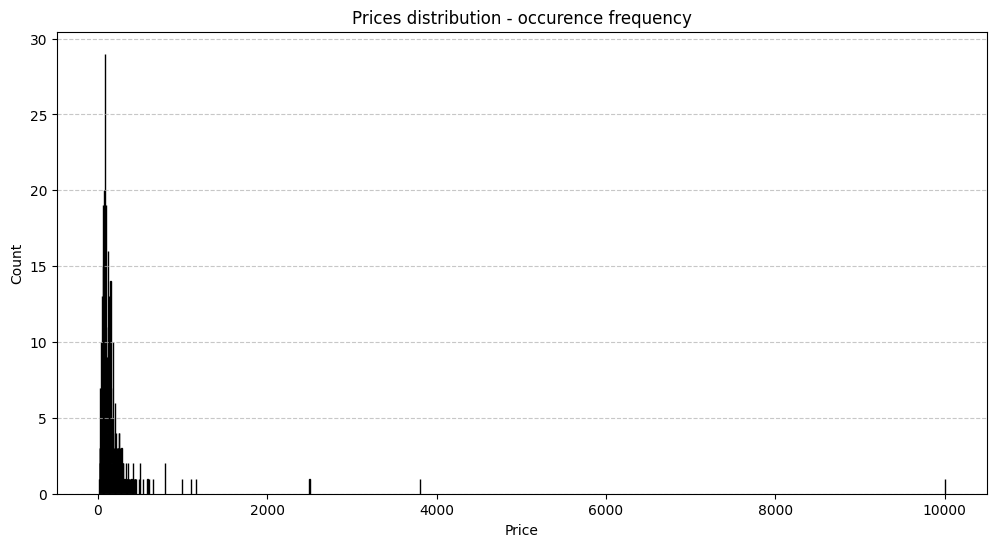

In [109]:
prices_distro = listings_df["price_numeric"].value_counts(dropna=True)
plt.figure(figsize=(12, 6))

plt.bar(prices_distro.index, prices_distro.values, color=["skyblue", "orange"], edgecolor="black")
plt.title("Prices distribution - occurence frequency")
plt.xlabel("Price")
plt.ylabel("Count")
# plt.xticks(prices_distro.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [98]:
price_info = listings_df["price_numeric"].dropna()

price_distro_info = {
    "min value": price_info.min(),
    "max value": price_info.max(),
    "median": price_info.median(),
    "mean": price_info.mean(),
    "std": price_info.std()
}

print("Prices distribution:")
price_distro_info

Prices distribution:


{'min value': np.float64(17.0),
 'max value': np.float64(9999.0),
 'median': np.float64(98.5),
 'mean': np.float64(143.64660831509846),
 'std': np.float64(372.03875249293776)}

- jak mozna zauwazyc, odchylenie standardowe jest bardzo wysokie, co wskazuje na duza rónorodność w zakresie cen noclegów oferowanych przez portal klienta
- jednakze, najczęściej występujące ceny oferowane noclegów, jak i średnia wszystkich cen znajdują się w okolicy ceny 100-150 $
 

__Dane pokazują, iz w ofercie portalu znajdują się noclegi z róznych półek cenowych, natomiast nie pozwala to stwierdzić, czy w zdarzały się sytuacje sztucznego zawyzania cen. W celu wyciągnięcia wstępnych wniosków o wachaniach cen ofert przeanalizowane zostaną dane z spisu kalendarzowego (calendar.csv) dostarczające informacje o cenie noclegu oraz stanie rezerwacji w danym dniu__

In [114]:
calendar_df = pd.read_csv("../data/calendar.csv", skip_blank_lines=False)
calendar_df.head()

,listing_id,date,available,price,adjusted_price,minimum_nights,maximum_nights
0,20858,2024-12-21,f,$129.00,NaN,3,1125
1,20858,2024-12-22,f,$129.00,NaN,3,1125
2,20858,2024-12-23,f,$129.00,NaN,3,1125
3,20858,2024-12-24,t,$129.00,NaN,3,1125
4,20858,2024-12-25,t,$129.00,NaN,3,1125


- w wyniku rozmowy z klientem ustalone zostało, ze kolumna 'adjusted_price' zostanie pominieta w wstępnych analizach, gdyz klient nie jest w stanie dostarczyć tych danych
- dlatego kolumna 'price' została uzyta jako niosąca informacje o cenie w danym okresie (wartość inna niz cena bazowa, dostosowana do popytu związanego z sezonowością)

- ponizej przedstawiona jest średnia kwartalna cena losowej oferty portalu 'Nocarz' 

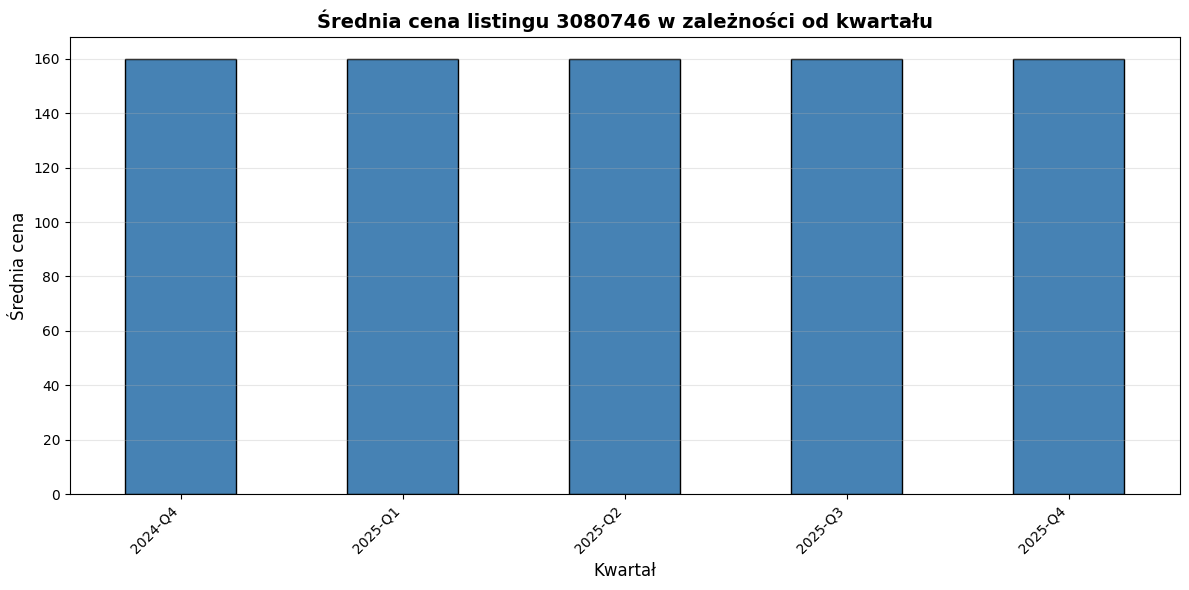

Listing ID: 3080746

Średnie ceny po kwartale:
year_quarter
2024-Q4    160.0
2025-Q1    160.0
2025-Q2    160.0
2025-Q3    160.0
2025-Q4    160.0
Name: price_numeric, dtype: float64


In [115]:
mod_calendar_df = calendar_df.copy()
mod_calendar_df["price_numeric"] = mod_calendar_df["price"].str.replace('$', '').str.replace(',', '').astype(float)
mod_calendar_df["date"] = pd.to_datetime(mod_calendar_df["date"])

mod_calendar_df["year_quarter"] = mod_calendar_df["date"].dt.year.astype(str) + '-Q' +  mod_calendar_df["date"].dt.quarter.astype(str)

# each time random listing data is checked
listing_id = mod_calendar_df['listing_id'].iloc[np.random.choice(range(len(mod_calendar_df['listing_id'])))]
listing_prices = mod_calendar_df[mod_calendar_df['listing_id'] == listing_id].copy()

quarterly_avg = listing_prices.groupby('year_quarter')['price_numeric'].mean()

plt.figure(figsize=(12, 6))
quarterly_avg.plot(kind="bar", color="steelblue", edgecolor="black")
plt.xlabel("Kwartał", fontsize=12)
plt.ylabel("Średnia cena", fontsize=12)
plt.title(f"Średnia cena listingu {listing_id} w zależności od kwartału", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Listing ID: {listing_id}\n")
print(f"Średnie ceny po kwartale:\n{quarterly_avg}")

- Jak widać, średnia cena oferty czy tez jej odchylenie w danym kwartale pozostają stałe więc zawyzanie cen prawdopodobnie nie będzie związane z sezonowością

Teraz przeprowadzona zostanie analiza cen noclegów z perspektywy dziennej 

In [ ]:
listings_price_distro = {}

for listing_id in mod_calendar_df['listing_id'].unique():
    listing_per_id_df = mod_calendar_df[mod_calendar_df['listing_id'] == listing_id].copy()
    listing_prices = listing_per_id_df["price_numeric"]
    listings_price_distro[listing_id] = {
        "min": listing_prices.min(),
        "max": listing_prices.max(),
        "mean": listing_prices.mean(),
        "median": listing_prices.median(),
        "std": listing_prices.std()
    }

pprint(listings_price_distro)


{np.int64(20858): {'max': np.float64(129.0),
                   'mean': np.float64(129.0),
                   'median': np.float64(129.0),
                   'min': np.float64(129.0),
                   'std': np.float64(0.0)},
 np.int64(29279): {'max': np.float64(130.0),
                   'mean': np.float64(130.0),
                   'median': np.float64(130.0),
                   'min': np.float64(130.0),
                   'std': np.float64(0.0)},
 np.int64(64014): {'max': np.float64(180.0),
                   'mean': np.float64(180.0),
                   'median': np.float64(180.0),
                   'min': np.float64(180.0),
                   'std': np.float64(0.0)},
 np.int64(81081): {'max': np.float64(73.0),
                   'mean': np.float64(73.0),
                   'median': np.float64(73.0),
                   'min': np.float64(73.0),
                   'std': np.float64(0.0)},
 np.int64(85560): {'max': np.float64(110.0),
                   'mean': np.float64(110.0),
 

In [118]:
nonzero_std_listings = [listing_id for listing_id in listings_price_distro if listings_price_distro[listing_id]["std"] != 0]
print(f"Liczba ofert o nie-zerowym odchyleniu standardowym cen z badanego okresu: {len(nonzero_std_listings)}")

Liczba ofert o nie-zerowym odchyleniu standardowym cen z badanego okresu: 0


- cena 'price' przedstawiona w spisie kalendarzowym dostępnych noclegów (calendar.csv) jest stała i nie zmienia się w kolejnych dniach (czy tez kwartałach) obowiązywania oferty

Ponizej sprawdzona zosatała zaleność dostępności noclegów w zalezności od ceny oferty 

In [ ]:
unqiue_prices = [price for price in mod_calendar_df["price_numeric"].unique()]
price_availability_distro = {}

for price in unqiue_prices:
    data_per_price = mod_calendar_df[mod_calendar_df["price_numeric"] == price]
    price_availability_distro[price] = len(data_per_price[data_per_price["available"] == "f"])  # available == f(alse)
    
pprint(price_availability_distro)

{np.float64(10.0): 730,
 np.float64(12.0): 730,
 np.float64(14.0): 365,
 np.float64(15.0): 814,
 np.float64(16.0): 365,
 np.float64(17.0): 317,
 np.float64(18.0): 365,
 np.float64(19.0): 1095,
 np.float64(20.0): 3163,
 np.float64(21.0): 365,
 np.float64(22.0): 742,
 np.float64(23.0): 2412,
 np.float64(24.0): 1019,
 np.float64(25.0): 8198,
 np.float64(26.0): 1125,
 np.float64(27.0): 929,
 np.float64(28.0): 1725,
 np.float64(29.0): 2874,
 np.float64(30.0): 12487,
 np.float64(31.0): 731,
 np.float64(32.0): 2595,
 np.float64(33.0): 953,
 np.float64(34.0): 306,
 np.float64(35.0): 9550,
 np.float64(36.0): 1026,
 np.float64(37.0): 960,
 np.float64(38.0): 1663,
 np.float64(39.0): 1821,
 np.float64(40.0): 12097,
 np.float64(41.0): 882,
 np.float64(42.0): 1430,
 np.float64(43.0): 1439,
 np.float64(44.0): 801,
 np.float64(45.0): 9279,
 np.float64(46.0): 376,
 np.float64(47.0): 493,
 np.float64(48.0): 2599,
 np.float64(49.0): 3775,
 np.float64(50.0): 12241,
 np.float64(51.0): 550,
 np.float64(52.0

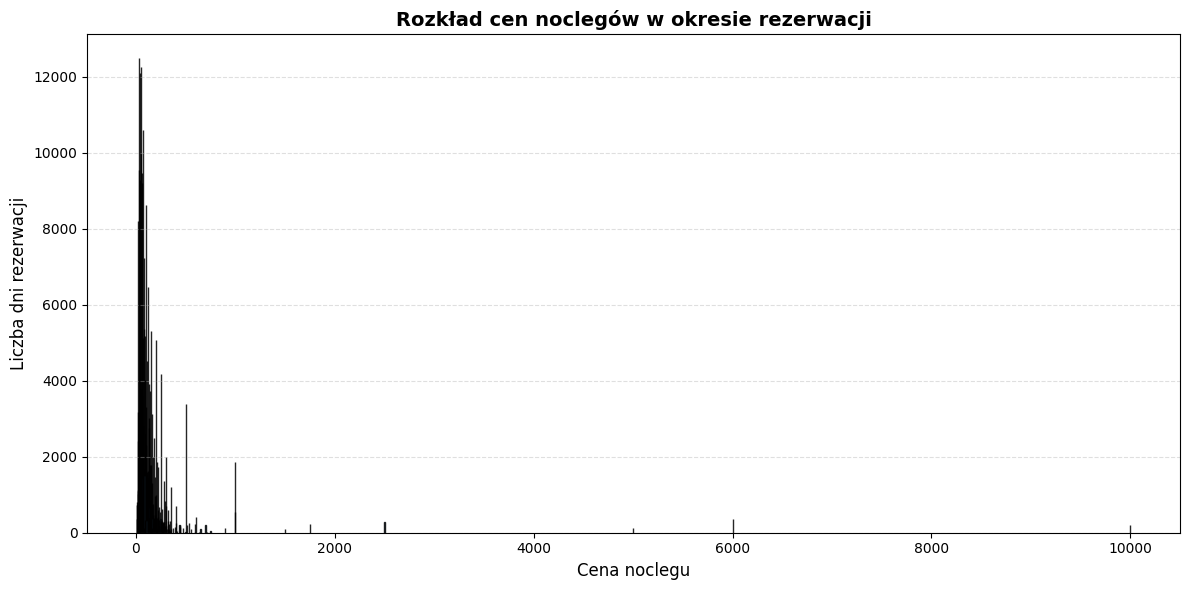

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(price_availability_distro.keys(), price_availability_distro.values(), color="steelblue", edgecolor="black", alpha=0.85)
# plt.pie(price_availability_distro.values(), labels=price_availability_distro.keys())
plt.title("Rozkład cen noclegów w okresie rezerwacji", fontsize=14, fontweight="bold")
plt.xlabel("Cena noclegu", fontsize=12)
plt.ylabel("Liczba dni rezerwacji", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()